[80 86  7]


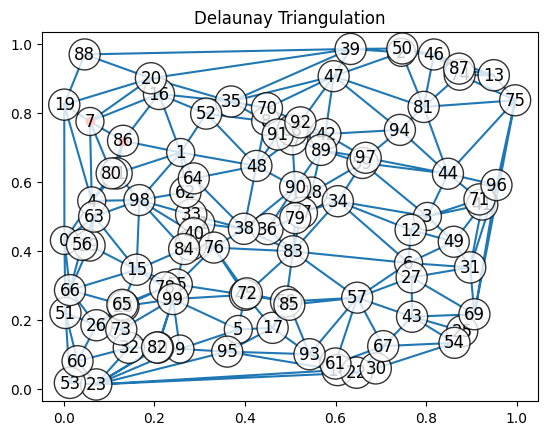

In [1]:
import numpy as np
from scipy.spatial import Delaunay
import matplotlib.pyplot as plt

# Define points
points = np.random.rand(100, 2)  # 10 random points in 2D space

# Perform Delaunay triangulation
tri = Delaunay(points)

# Plot the points and the triangulation
plt.triplot(points[:, 0], points[:, 1], tri.simplices)
# plt.plot(points[:, 0] Annotate each point with its index
for i, (x, y) in enumerate(points):
    plt.text(x, y, str(i), fontsize=12, ha='center', va='center', 
             bbox=dict(boxstyle='circle', facecolor='white', alpha=0.8))
tri.simplices
print(tri.simplices[0])
for i in tri.simplices[0]:
    plt.plot(points[i, 0], points[i, 1], 'o', color='red')
plt.title("Delaunay Triangulation")
plt.show()


In [2]:
import pandas as pd
df_res = pd.read_csv('inversion_results.csv', index_col=0)
print(df_res.columns)
df_mod = pd.read_csv('inversion_results_models.csv')

df_overview = df_res.pivot_table(
    index=['site_id'],
    values=['date', 'daytime', 'latitude', 'longitude', 'elevation'],
    aggfunc='first'
)
df_overview['site_id'] = df_overview.index

Index(['site_id', 'dbdt', 'error', 'inuse_auto', 'inuse_manual', 'time',
       'gate_id', 'system_id', 'date', 'latitude', 'longitude', 'elevation',
       'daytime', 'error_lb', 'error_ub', 'log10_dbdt', 'sys_gate', 'data_id',
       'include', 'dbdt_syn'],
      dtype='object')


In [3]:
import utm

In [4]:
utmx,utmy,zone_number,zone_letter = utm.from_latlon(df_overview['latitude'].values, df_overview['longitude'].values)
df_overview['utm_x'] = utmx
df_overview['utm_y'] = utmy
df_overview['zone_number'] = zone_number
df_overview['zone_letter'] = zone_letter

In [5]:
points.shape

(100, 2)

In [6]:
x = np.arange(5)
y = np.arange(5)
np.vstack((x,y)).shape

(2, 5)

[36 35 34]


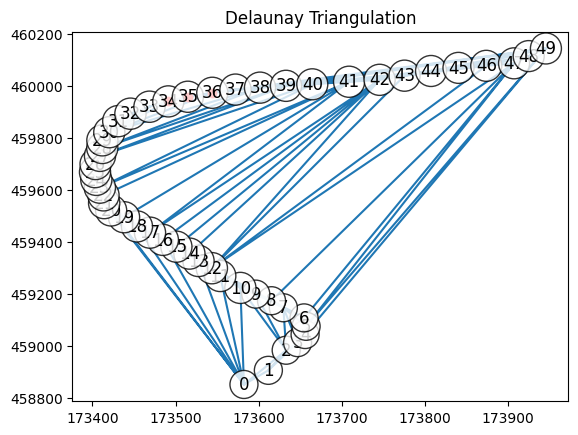

In [7]:
points = df_overview[['utm_x', 'utm_y']].values

tri = Delaunay(points)

# Plot the points and the triangulation
plt.triplot(points[:, 0], points[:, 1], tri.simplices)
for i, (x, y) in enumerate(points):
    plt.text(x, y, str(i), fontsize=12, ha='center', va='center', 
             bbox=dict(boxstyle='circle', facecolor='white', alpha=0.8))
tri.simplices
print(tri.simplices[0])
for i in tri.simplices[0]:
    plt.plot(points[i, 0], points[i, 1], 'o', color='red')
plt.title("Delaunay Triangulation")
plt.show()


In [8]:
connected_pairs = []
for simplex in tri.simplices:
    simplex.sort()
    p1 = int(simplex[0]), int(simplex[1])
    p2 = int(simplex[0]), int(simplex[2])
    p3 = int(simplex[1]), int(simplex[2])
    if p1 not in connected_pairs:
        connected_pairs.append(p1)
    if p2 not in connected_pairs:
        connected_pairs.append(p2)
    if p3 not in connected_pairs:
        connected_pairs.append(p3)

all_dist = np.zeros(len(connected_pairs))


for i,pair in enumerate(connected_pairs):
    p1 = points[pair[0]]
    p2 = points[pair[1]]
    all_dist[i] = np.linalg.norm(p1 - p2)

min_dist = np.zeros(len(points))
min_dist.fill(all_dist.max())


for i,pair in enumerate(connected_pairs):    
    min_dist[pair[0]] = min(min_dist[pair[0]], all_dist[i])

print(np.mean(all_dist))
print(np.mean(min_dist))

constraint_strength = min_dist.mean() / all_dist


207.82116808157357
56.85729084199931


In [11]:
n_layers = 5
c_mat = np.zeros((len(connected_pairs), len(points)*n_layers))
for i, pair in enumerate(connected_pairs):
    c_mat[i, ::n_layers][pair[0]] =  constraint_strength[i]
    c_mat[i, ::n_layers][pair[1]] = -constraint_strength[i]

c_mat = np.repeat(c_mat, n_layers, axis=0)

for i in range(n_layers):
    c_mat[i::n_layers, :] = np.roll(c_mat[i::n_layers, :], i, axis=1)

<Figure size 640x480 with 0 Axes>

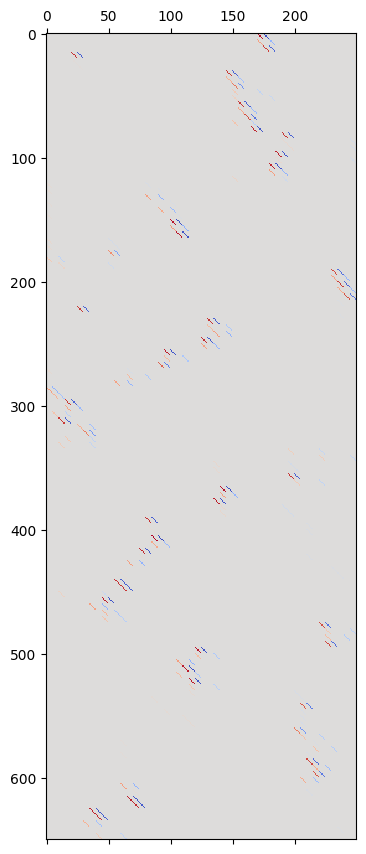

In [12]:
plt.figure()
plt.matshow(c_mat, cmap='coolwarm', aspect='auto')
# plt.plot(c_mat.sum(1))